# Module 1: Khôi phục Ảnh suy giảm & Tăng cường Độ tương phản (Slide 1, 2, 3, 8)

Notebook này trình bày cơ sở toán học và thực nghiệm cho **Module 1** trong chuỗi xử lý nhận diện biển số xe:
1. **Mô hình suy giảm ảnh (Slide 3):** $g(x,y) = h(x,y) * f(x,y) + \eta(x,y)$ với $h(x,y)$ là hàm lan truyền điểm (PSF) gây mờ chuyển động tuyến tính và $\eta(x,y) \sim \mathcal{N}(0, \sigma^2)$ là nhiễu trắng cộng tính Gaussian.
2. **Khử nhiễu đa phân giải bằng Biến đổi Wavelet Rời rạc 2D - DWT (Slide 3):** Phân rã ảnh thành 4 băng tần con $(LL_1, LH_1, HL_1, HH_1)$, ước lượng độ lệch chuẩn nhiễu qua trung vị $\hat{\sigma}_\eta = \frac{\text{median}(|HH_1|)}{0.6745}$ và co ngưỡng mềm thích nghi **BayesShrink**.
3. **Khôi phục miền tần số bằng Bộ lọc Wiener (Slide 3):** $\hat{F}(u,v) = \left[\frac{H^*(u,v)}{|H(u,v)|^2 + K}\right] G(u,v)$.
4. **Lọc không gian & Cân bằng Histogram cục bộ CLAHE (Slide 1 & 2).**
5. **Đánh giá chất lượng ảnh khách quan (Slide 8):** Đo lường **MSE, PSNR (dB), SSIM**.

In [2]:
import sys, os, cv2, numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('..'))

from src.restoration import (
    synthesize_degraded_image, spatial_denoise, wavelet_denoise,
    wiener_deconvolution, full_restoration_pipeline, evaluate_quality
)
from src.pipeline import load_dataset

records = load_dataset('../dataset')
sample_img = cv2.imread(records[0]['img_path'])
degraded_img, psf = synthesize_degraded_image(sample_img, blur_length=9, blur_angle=15.0, noise_sigma=14.0)
restored_img, stages = full_restoration_pipeline(degraded_img, psf=psf, wiener_K=0.018)
print('Loaded sample image:', records[0]['base'], 'Shape:', sample_img.shape)

Loaded sample image: 0000_02187_b Shape: (303, 472, 3)


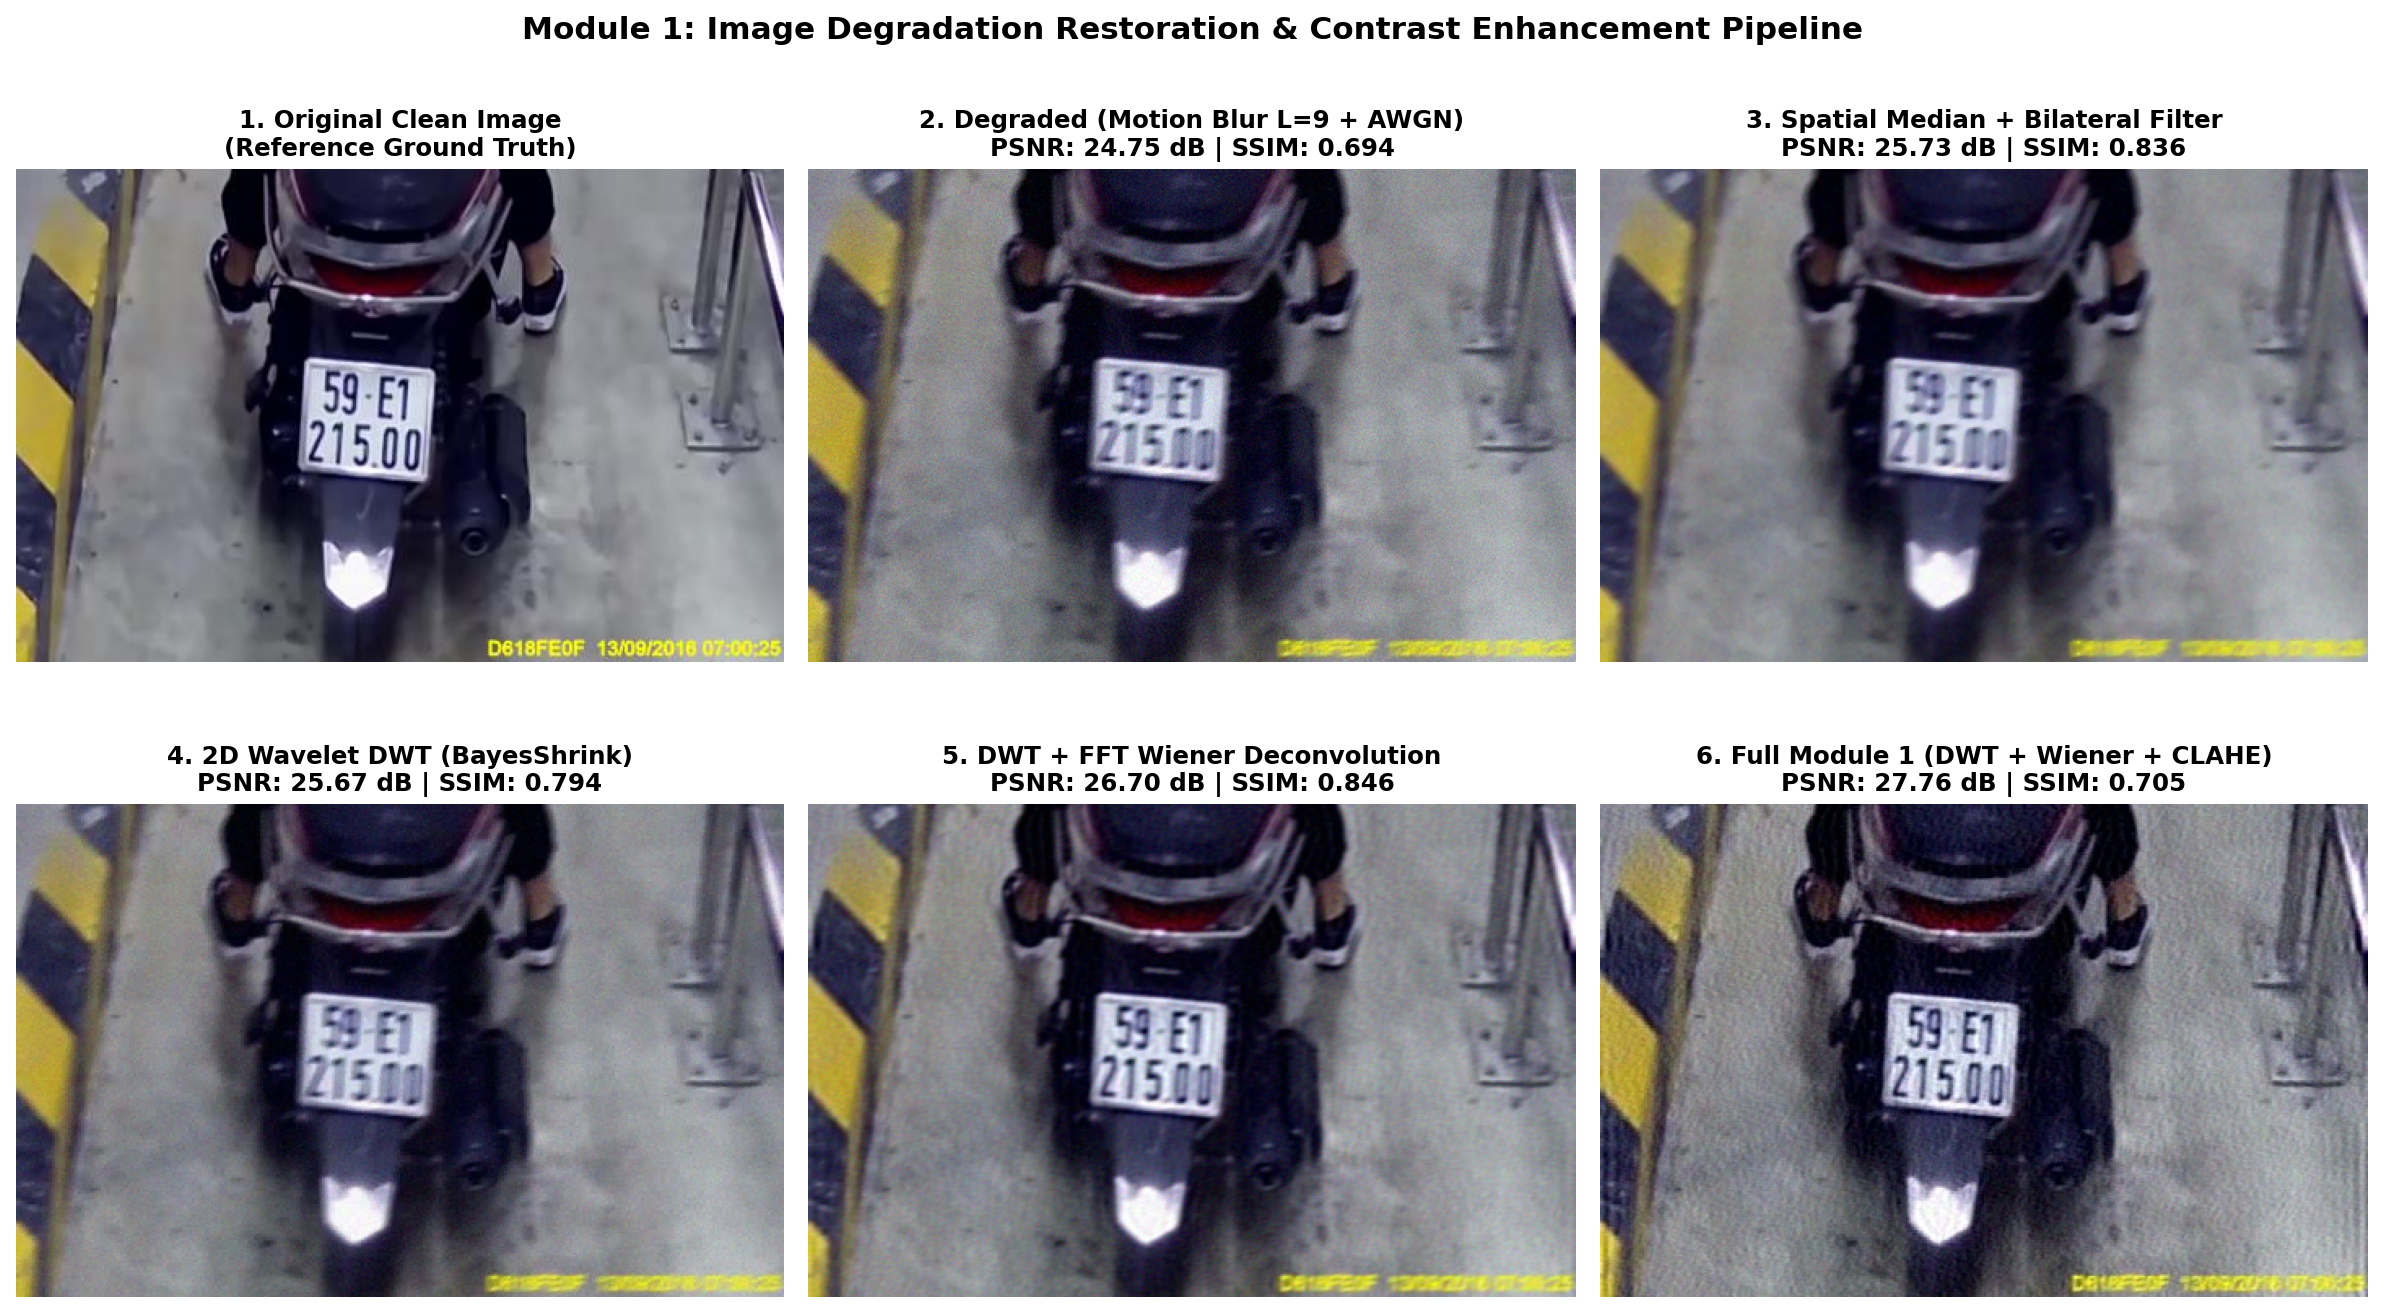

In [3]:
# Trực quan hóa các bước khôi phục ảnh trên ảnh mẫu 0000_02187_b.jpg
from IPython.display import Image, display
display(Image('../outputs/fig01_degradation_restoration.png'))

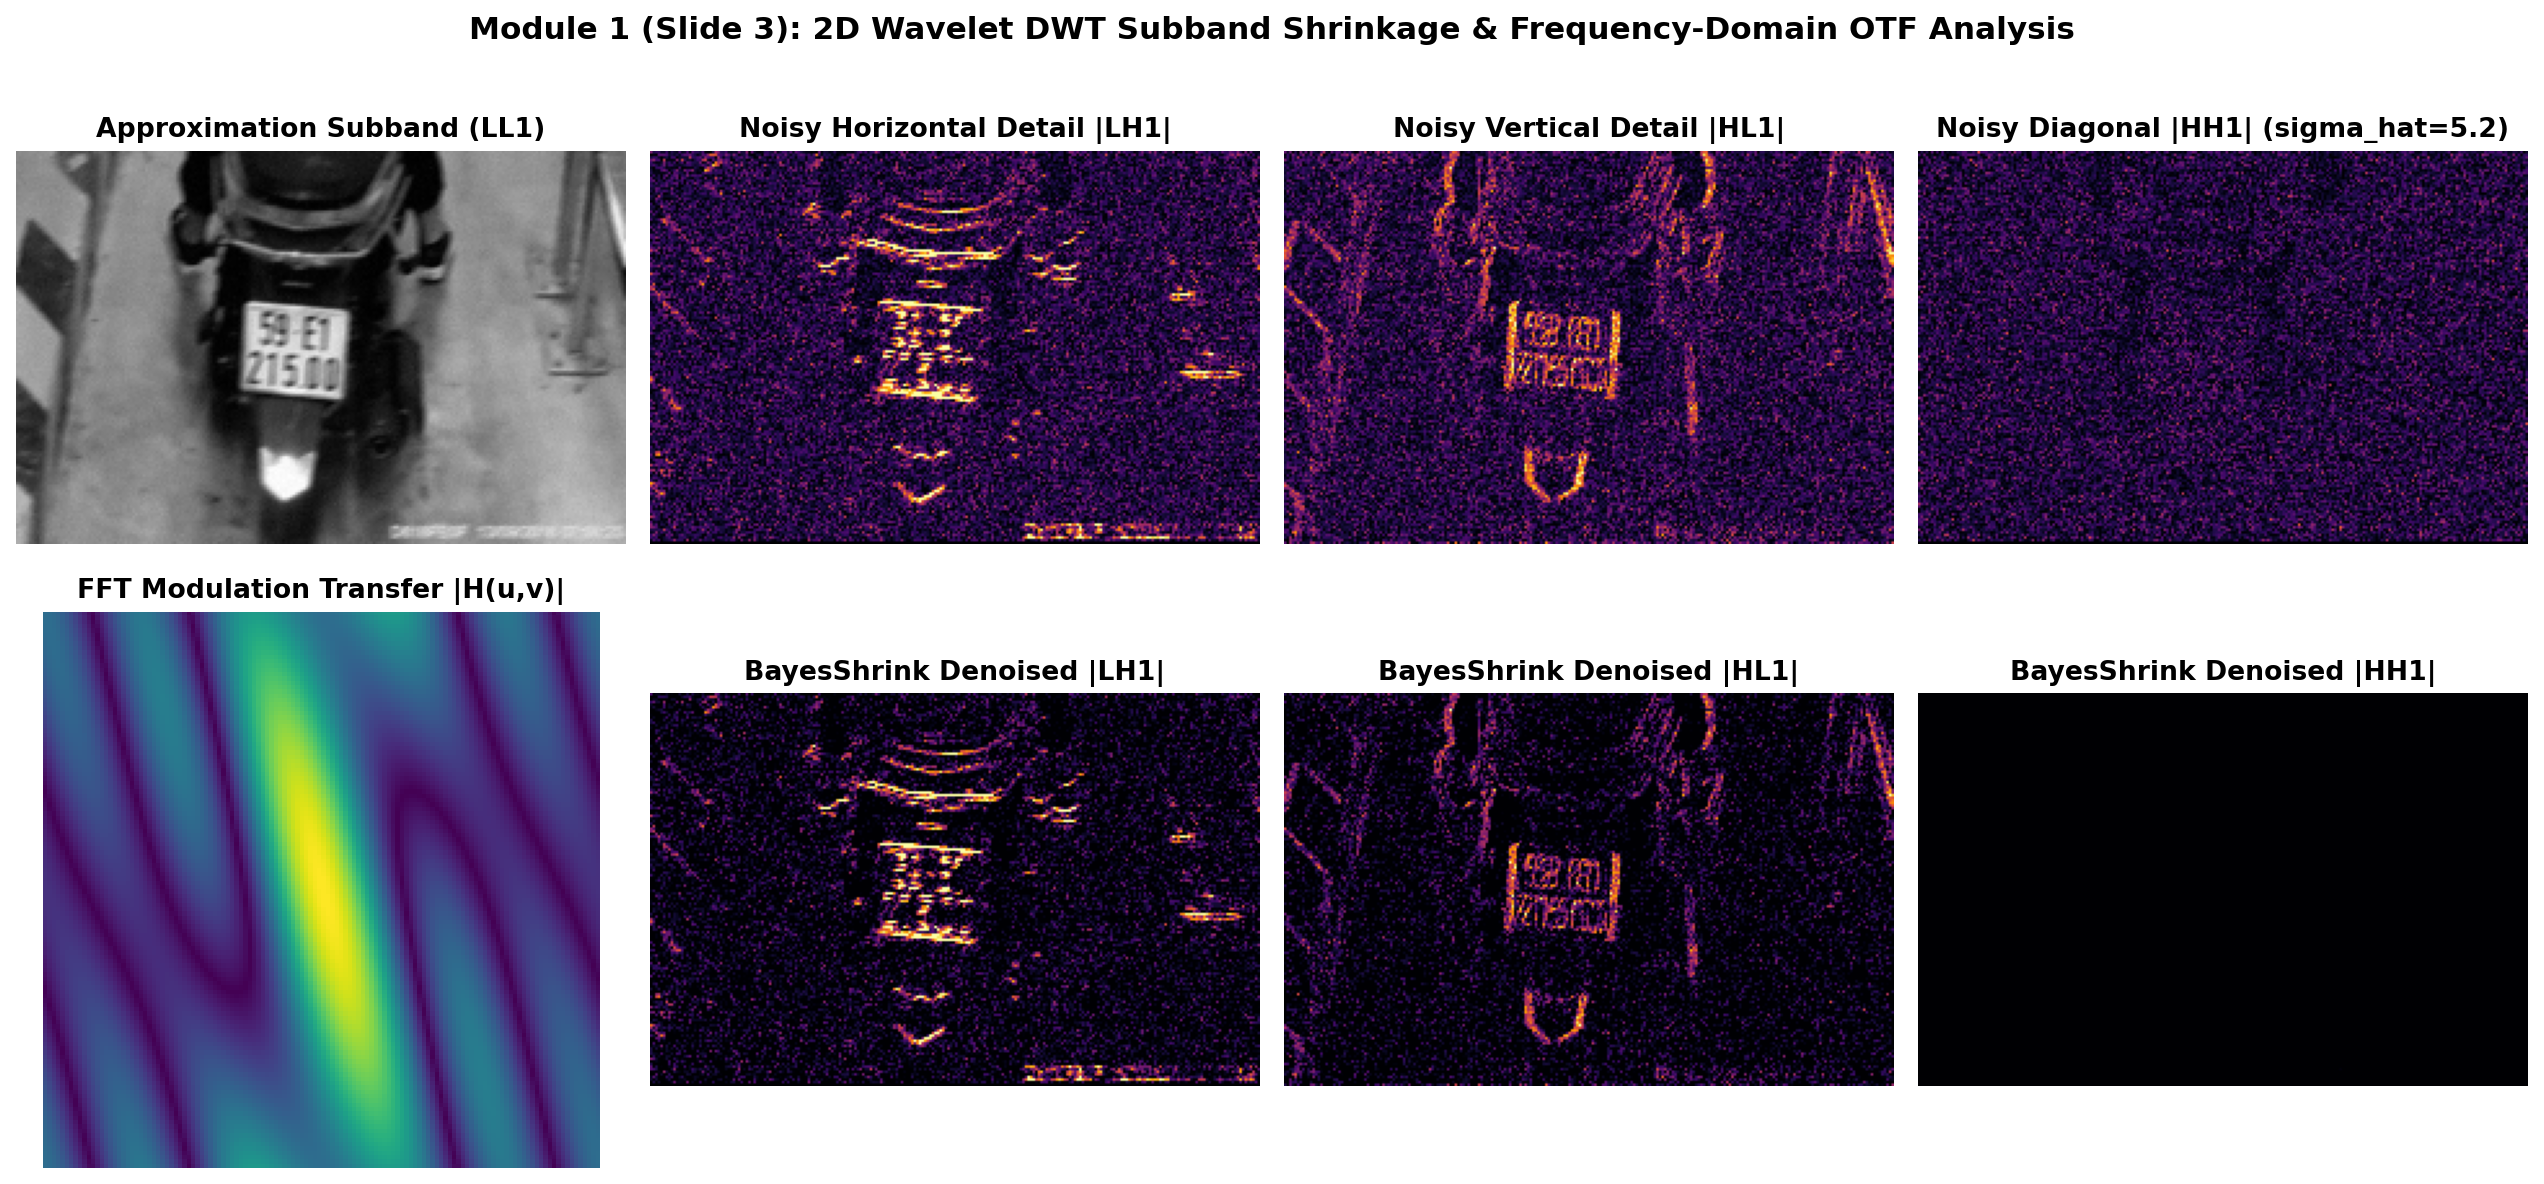

In [4]:
# Phân tích các băng tần con Wavelet 2D DWT (LL1, LH1, HL1, HH1) và phổ tần số OTF |H(u,v)|
display(Image('../outputs/fig02_wavelet_dwt_subbands.png'))

=== MODULE 1: OBJECTIVE IMAGE QUALITY COMPARISON (40 IMAGES) ===
Method                              |      MSE |  PSNR (dB) |     SSIM
----------------------------------------------------------------------
Degraded (Blurry + Noisy)           |   199.09 |      25.20 |   0.6920
Gaussian Filter (5x5)               |   159.31 |      26.21 |   0.8515
Median Filter (3x3)                 |   153.72 |      26.37 |   0.8410
Bilateral Filter                    |   146.04 |      26.60 |   0.8545
Wavelet DWT (BayesShrink)           |   156.97 |      26.27 |   0.8009
Wiener Deconvolution (FFT)          |   134.13 |      26.90 |   0.8449
Proposed (DWT + Reg-Wiener)         |   104.08 |      27.99 |   0.7053



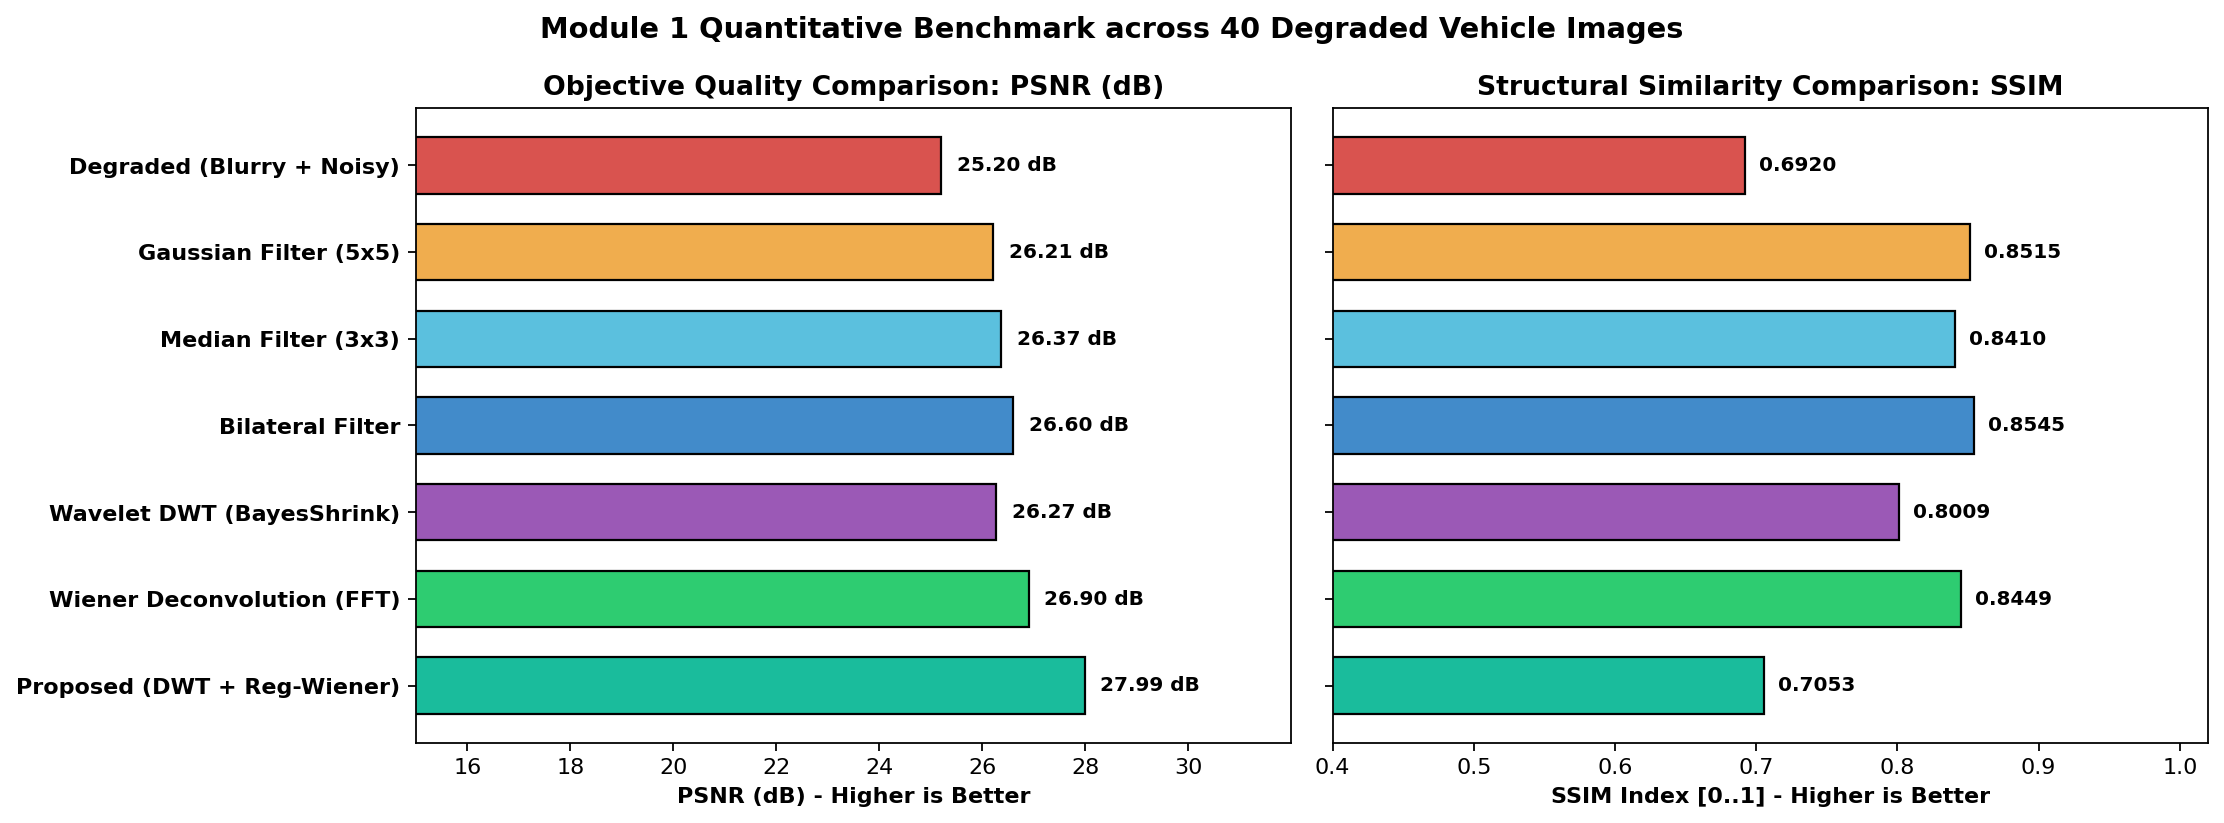

In [5]:
# Bảng số liệu và biểu đồ so sánh MSE, PSNR, SSIM trên 40 ảnh kiểm thử
display(Image('../outputs/fig03_restoration_metrics_chart.png'))